# FIFA World Cup 2034 — Weather Analysis for Match Scheduling

This notebook analyzes 10 years (2015–2024) of hourly weather across the five
Saudi host cities (Riyadh, Jeddah, Al Khobar, Abha, NEOM) to support smart
match scheduling that balances fan comfort and player safety.

**Pipeline:** Data Collection → EDA → Feature Engineering (WBGT, target, cyclical encoding, lag features, city encoding) → Modeling (next phase)

**Data source:** Open-Meteo Historical Archive API (hourly, 2015–2024, 5 host cities).

## Data Collection (reference)

The dataset was collected from the **Open-Meteo Historical Archive API** for the
5 FIFA World Cup 2034 host cities — hourly records, 2015–2024, timezone Asia/Riyadh.

> The collection script below is included **for reference only**, to document how
> the raw data was obtained. It was executed **once in a separate data-collection
> notebook** to produce `host_cities_weather_2015_2024.csv`. This analysis notebook
> simply loads that saved CSV, so the cell below is **not run here**.

In [ ]:
# ============================================================================
#  DATA COLLECTION SCRIPT — FOR REFERENCE ONLY (not executed in this notebook)
#  This documents how the raw weather data was gathered from the Open-Meteo API.
#  It was run once in a separate data-collection notebook to create the CSV file
#  that the analysis below loads. Re-running it here is unnecessary.
# ============================================================================

import time
import requests
import pandas as pd

# ---------- Configuration ----------
CITIES = {
    "Riyadh":    {"lat": 24.7136, "lon": 46.6753},
    "Jeddah":    {"lat": 21.4858, "lon": 39.1925},
    "Al Khobar": {"lat": 26.2794, "lon": 50.2083},
    "Abha":      {"lat": 18.2164, "lon": 42.5053},
    "NEOM":      {"lat": 27.9600, "lon": 35.4500},
}

START_DATE = "2015-01-01"
END_DATE   = "2024-12-31"

HOURLY_VARS = [
    "temperature_2m", "relative_humidity_2m", "wind_speed_10m",
    "apparent_temperature", "precipitation", "shortwave_radiation",
]
BASE_URL = "https://archive-api.open-meteo.com/v1/archive"


# ---------- Fetch a single city ----------
def fetch_city(name, lat, lon):
    params = {
        "latitude": lat, "longitude": lon,
        "start_date": START_DATE, "end_date": END_DATE,
        "hourly": ",".join(HOURLY_VARS), "timezone": "Asia/Riyadh",
    }
    print(f"  Downloading {name} ...")
    r = requests.get(BASE_URL, params=params, timeout=180)
    r.raise_for_status()

    df = pd.DataFrame(r.json()["hourly"]).rename(columns={
        "time": "datetime",
        "temperature_2m": "Temperature",
        "relative_humidity_2m": "Humidity",
        "wind_speed_10m": "WindSpeed",
        "apparent_temperature": "ApparentTemp",
        "precipitation": "Precipitation",
        "shortwave_radiation": "SolarRadiation",
    })
    df["datetime"] = pd.to_datetime(df["datetime"])
    df.insert(0, "City", name)

    # Simple time columns (real feature engineering — WBGT, lags — done later)
    df["Hour"] = df["datetime"].dt.hour
    df["Month"] = df["datetime"].dt.month
    df["DayOfWeek"] = df["datetime"].dt.dayofweek
    return df


# ---------- Fetch all cities and combine ----------
def fetch_all():
    frames = []
    for name, c in CITIES.items():
        frames.append(fetch_city(name, c["lat"], c["lon"]))
        time.sleep(1)  # be polite to the API between requests
    return pd.concat(frames, ignore_index=True)


# ---------- Run ----------
df = fetch_all()
df.to_csv("host_cities_weather_2015_2024.csv", index=False)

print("\nDone!")
print(f"Rows: {len(df):,}")
print(f"Period: {df['datetime'].min()} -> {df['datetime'].max()}")
print(df.head())

# Download the file to your computer
from google.colab import files
files.download("host_cities_weather_2015_2024.csv")

# 1. Exploratory Data Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (11, 5)

num_cols = ["Temperature", "Humidity", "WindSpeed",
              "ApparentTemp", "Precipitation", "SolarRadiation"]

df = pd.read_csv("host_cities_weather_2015_2024.csv")
df["datetime"] = pd.to_datetime(df["datetime"])

print("the shape:", df.shape)
df.head()

the shape: (438360, 11)


,City,datetime,Temperature,Humidity,WindSpeed,ApparentTemp,Precipitation,SolarRadiation,Hour,Month,DayOfWeek
0,Riyadh,2015-01-01 00:00:00,12.9,50,10.4,9.7,0.0,0.0,0,1,3
1,Riyadh,2015-01-01 01:00:00,11.7,54,8.6,8.7,0.0,0.0,1,1,3
2,Riyadh,2015-01-01 02:00:00,10.5,59,7.9,7.7,0.0,0.0,2,1,3
3,Riyadh,2015-01-01 03:00:00,9.7,62,8.2,6.9,0.0,0.0,3,1,3
4,Riyadh,2015-01-01 04:00:00,9.2,65,8.0,6.3,0.0,0.0,4,1,3


In [2]:
# Show last 5 rows
df.tail()


,City,datetime,Temperature,Humidity,WindSpeed,ApparentTemp,Precipitation,SolarRadiation,Hour,Month,DayOfWeek
438355,NEOM,2024-12-31 19:00:00,17.8,33,16.6,13.5,0.0,0.0,19,12,1
438356,NEOM,2024-12-31 20:00:00,16.6,37,14.8,12.7,0.0,0.0,20,12,1
438357,NEOM,2024-12-31 21:00:00,15.6,41,14.2,11.8,0.0,0.0,21,12,1
438358,NEOM,2024-12-31 22:00:00,14.7,45,13.5,11.1,0.0,0.0,22,12,1
438359,NEOM,2024-12-31 23:00:00,13.4,51,10.3,10.4,0.0,0.0,23,12,1


In [3]:
# Show random 5 rows
df.sample(5)

,City,datetime,Temperature,Humidity,WindSpeed,ApparentTemp,Precipitation,SolarRadiation,Hour,Month,DayOfWeek
286452,Abha,2017-09-03 12:00:00,23.4,39,7.2,22.7,0.0,669.0,12,9,6
58906,Riyadh,2021-09-20 10:00:00,34.8,13,17.9,31.3,0.0,716.0,10,9,0
7492,Riyadh,2015-11-09 04:00:00,18.6,58,11.6,16.9,0.0,0.0,4,11,0
293323,Abha,2018-06-16 19:00:00,24.3,19,1.3,21.9,0.0,25.0,19,6,5
163783,Jeddah,2023-09-07 07:00:00,29.7,89,9.5,36.9,0.0,35.0,7,9,3


In [4]:

# Returns (rows, columns)
print(df.shape)
# More readable
rows, cols =df.shape
print(f"Rows: {rows} | Columns: {cols}")

(438360, 11)
Rows: 438360 | Columns: 11


In [5]:
print(df.info())
display(df.describe().round(1))

print("\n  sum of null value " , df.isna().sum().sum())
print("duplicate value :", df.duplicated(subset=["City","datetime"]).sum())
# Because the same time naturally recurs between cities, we only consider it a duplicate if the city and time match.
print("columns for each city ")
print(df["City"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 438360 entries, 0 to 438359
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   City            438360 non-null  object        
 1   datetime        438360 non-null  datetime64[ns]
 2   Temperature     438360 non-null  float64       
 3   Humidity        438360 non-null  int64         
 4   WindSpeed       438360 non-null  float64       
 5   ApparentTemp    438360 non-null  float64       
 6   Precipitation   438360 non-null  float64       
 7   SolarRadiation  438360 non-null  float64       
 8   Hour            438360 non-null  int64         
 9   Month           438360 non-null  int64         
 10  DayOfWeek       438360 non-null  int64         
dtypes: datetime64[ns](1), float64(5), int64(4), object(1)
memory usage: 36.8+ MB
None


,datetime,Temperature,Humidity,WindSpeed,ApparentTemp,Precipitation,SolarRadiation,Hour,Month,DayOfWeek
count,438360,438360.0,438360.0,438360.0,438360.0,438360.0,438360.0,438360.0,438360.0,438360.0
mean,2020-01-01 11:30:00.000001792,25.6,45.6,13.6,24.6,0.0,247.5,11.5,6.5,3.0
min,2015-01-01 00:00:00,-0.8,1.0,0.0,-5.4,0.0,0.0,0.0,1.0,0.0
25%,2017-07-02 05:45:00,19.4,24.0,7.9,17.3,0.0,0.0,5.8,4.0,1.0
50%,2020-01-01 11:30:00,25.6,44.0,12.3,24.5,0.0,13.0,11.5,7.0,3.0
75%,2022-07-02 17:15:00,31.6,65.0,18.0,32.4,0.0,516.0,17.2,10.0,5.0
max,2024-12-31 23:00:00,49.1,100.0,54.4,49.3,45.7,1102.0,23.0,12.0,6.0
std,NaN,8.2,24.2,7.5,9.4,0.2,323.0,6.9,3.4,2.0



  sum of null value  0
duplicate value : 0
columns for each city 
City
Riyadh       87672
Jeddah       87672
Al Khobar    87672
Abha         87672
NEOM         87672
Name: count, dtype: int64


## Data Quality Summary

A consolidated check of completeness and physical validity before analysis.

In [6]:
# ===== Comprehensive data quality check =====
PHYS = {"Temperature": (-10, 60), "Humidity": (0, 100), "WindSpeed": (0, 200),
        "ApparentTemp": (-20, 70), "Precipitation": (0, 500), "SolarRadiation": (0, 1500)}

rows = []
for c in num_cols:
    Q1, Q3 = df[c].quantile(0.25), df[c].quantile(0.75)
    IQR = Q3 - Q1
    outliers = ((df[c] < Q1 - 1.5*IQR) | (df[c] > Q3 + 1.5*IQR)).sum()
    lo, hi = PHYS[c]
    invalid = ((df[c] < lo) | (df[c] > hi)).sum()
    rows.append([c, df[c].isna().sum(), round(df[c].min(),1),
                 round(df[c].max(),1), outliers, invalid])

quality = pd.DataFrame(rows, columns=["Column","Missing","Min","Max",
                                      "Outliers(IQR)","Invalid(physical)"])
print(quality.to_string(index=False))
print(f"\nTotal missing: {df.isna().sum().sum()} | Duplicates: "
      f"{df.duplicated(subset=['City','datetime']).sum()}")
print(f"Night solar radiation max (h0-4): {df[df.Hour<5].SolarRadiation.max()}")

        Column  Missing  Min    Max  Outliers(IQR)  Invalid(physical)
   Temperature        0 -0.8   49.1             30                  0
      Humidity        0  1.0  100.0              0                  0
     WindSpeed        0  0.0   54.4           7215                  0
  ApparentTemp        0 -5.4   49.3              1                  0
 Precipitation        0  0.0   45.7          12211                  0
SolarRadiation        0  0.0 1102.0              0                  0

Total missing: 0 | Duplicates: 0
Night solar radiation max (h0-4): 0.0




All columns pass quality checks: 0 missing, 0 duplicates, and 0 physically-invalid values. The IQR "outliers" in WindSpeed and Precipitation are genuine rare weather events (storms, rainy days), not errors, so they are retained — removing them would discard real extreme conditions relevant to scheduling. Night-time solar radiation is 0, confirming correct timezone alignment.

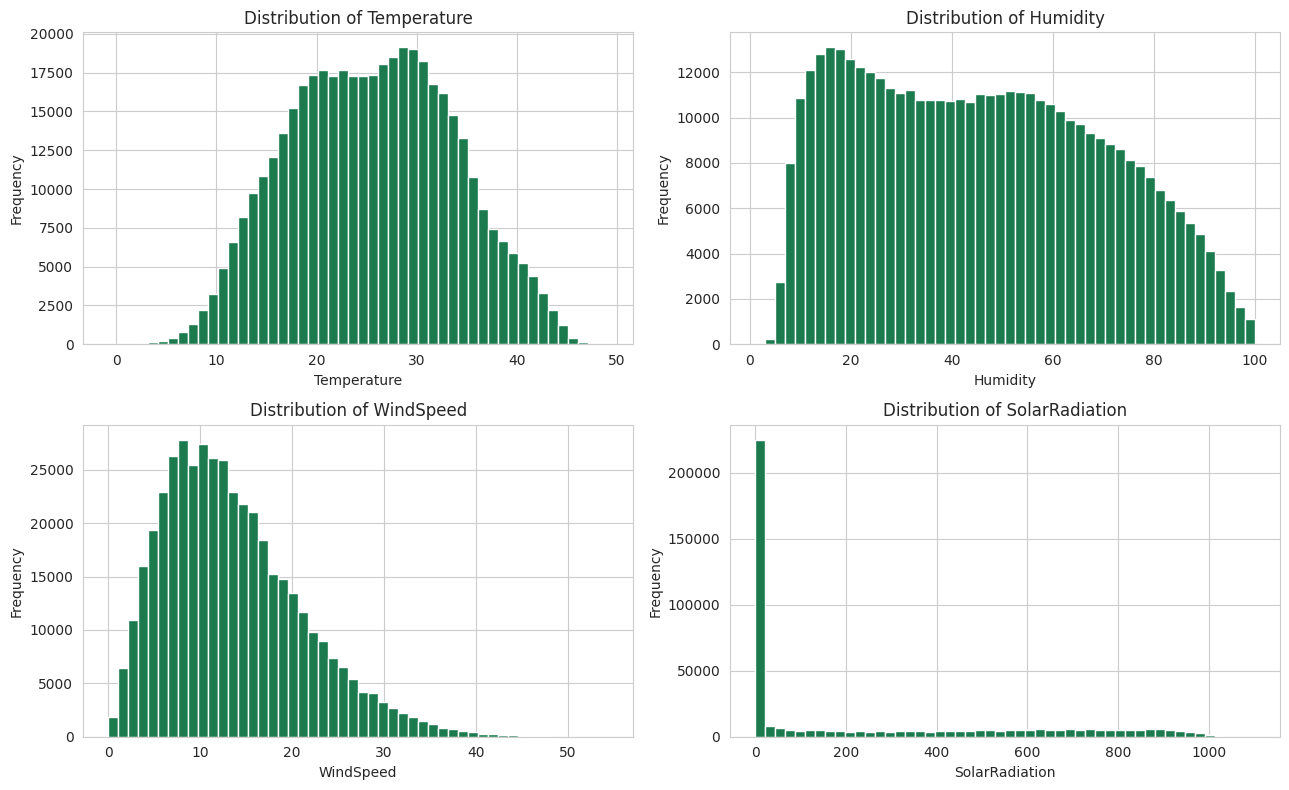

In [7]:
# ===== Distribution of main weather variables =====
# Goal: understand the range and shape of each variable across the full dataset.

cols = ["Temperature", "Humidity", "WindSpeed", "SolarRadiation"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, col in zip(axes.flat, cols):
    ax.hist(df[col], bins=50, color="#1b7a4e", edgecolor="white")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

Temperature is roughly bell-shaped and wide (0–49°C), reflecting both seasonal and city variation. Humidity spans the full 1–100% range because dry and humid cities are combined. WindSpeed is right-skewed (most hours are calm). SolarRadiation has a large spike at zero representing night-time hours. No abnormal values — data looks clean and realistic.

City comparison: I compare temperature, humidity, and heat across the five host cities to see how different their climates are — this directly affects how matches could be distributed.

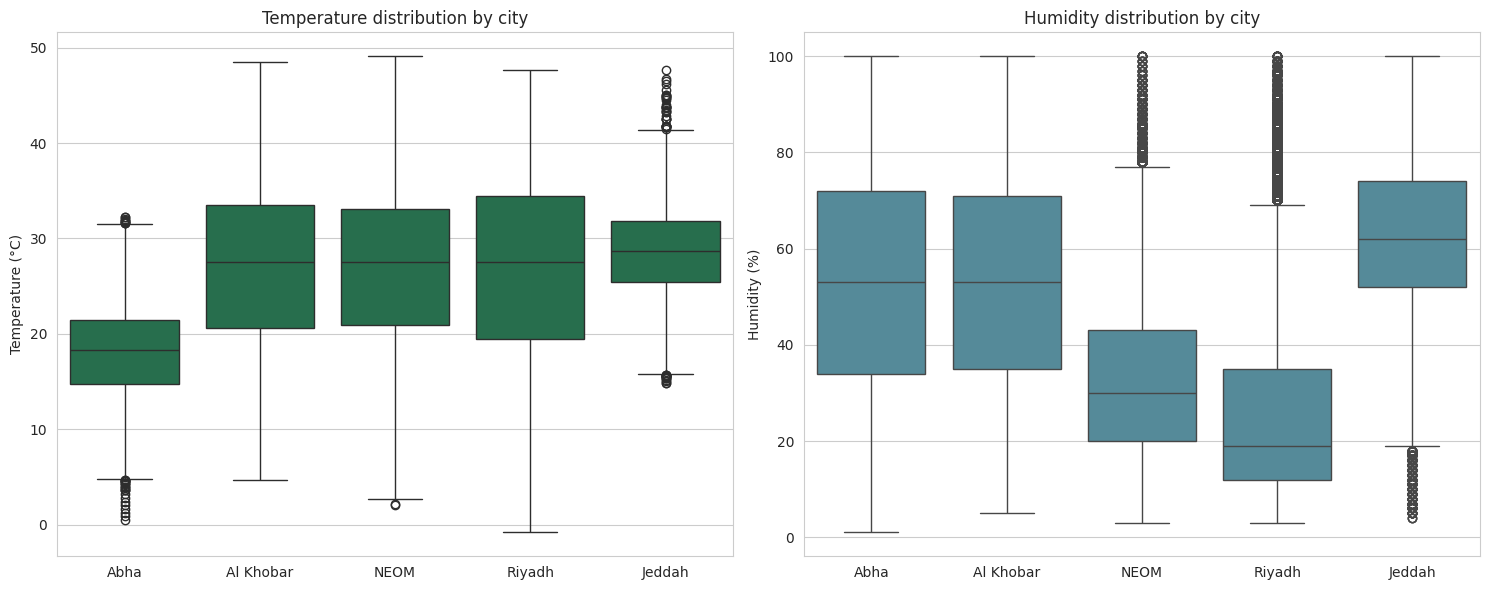

           Temperature  Humidity  WindSpeed
City                                       
Abha              18.3      53.1        8.7
Al Khobar         27.2      53.1       16.3
Jeddah            28.5      62.6       16.2
NEOM              27.0      32.9       12.9
Riyadh            26.9      26.5       13.6


In [8]:
# ===== City comparison: temperature & humidity =====
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# order cities by median temperature (coolest -> hottest)
order = df.groupby("City")["Temperature"].median().sort_values().index

sns.boxplot(data=df, x="City", y="Temperature", order=order,
            ax=axes[0], color="#1b7a4e")
axes[0].set_title("Temperature distribution by city")
axes[0].set_xlabel(""); axes[0].set_ylabel("Temperature (°C)")

sns.boxplot(data=df, x="City", y="Humidity", order=order,
            ax=axes[1], color="#4a90a4")
axes[1].set_title("Humidity distribution by city")
axes[1].set_xlabel(""); axes[1].set_ylabel("Humidity (%)")

plt.tight_layout()
plt.show()


# numeric summary
print(df.groupby("City")[["Temperature","Humidity","WindSpeed"]].mean().round(1))



Abha is clearly the coolest city (median 18°C) and the only realistic candidate for daytime matches. The other four are similar in temperature (~27°C) but differ sharply in humidity: Jeddah is the most humid (60%), while Riyadh is the driest (26%). This means heat stress differs even when temperature is similar — justifying the use of a combined index (WBGT) later.

### Outlier check (IQR)

In [9]:
#outliers
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)]
    print(f"{col}: {len(outliers)} outliers")

Temperature: 30 outliers
Humidity: 0 outliers
WindSpeed: 7215 outliers
ApparentTemp: 1 outliers
Precipitation: 12211 outliers
SolarRadiation: 0 outliers


the extreme values ​​here (especially in WindSpeed ​​and Rain) are not errors they are real, rare weather events (storms, rainy days). Therefore, I kept them all because  removing them would eliminate real, important extreme conditions for scheduling.

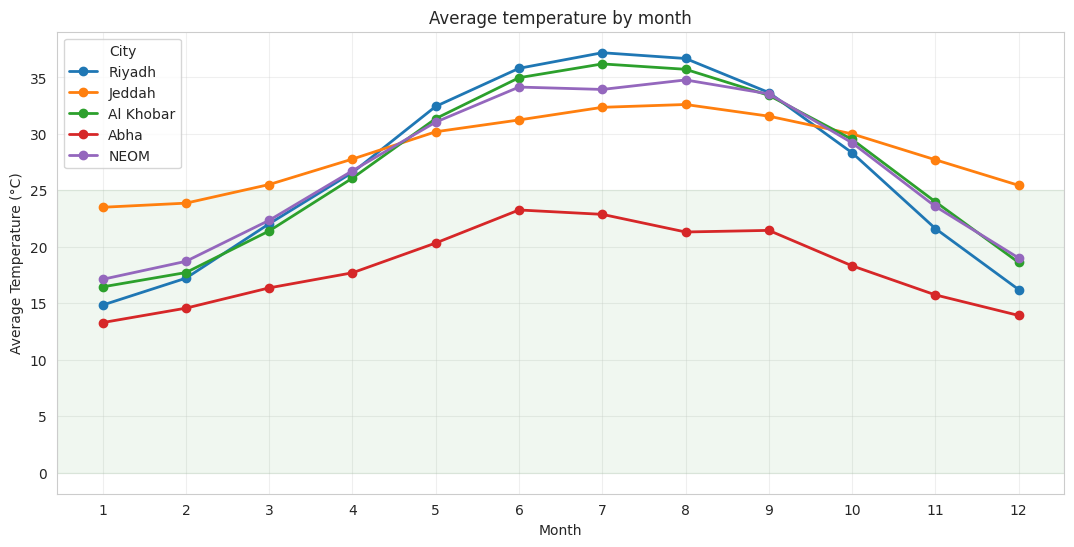

Month
1     17.0
2     18.4
3     21.5
4     25.0
5     29.1
6     31.9
7     32.5
8     32.2
9     30.7
10    27.1
11    22.5
12    18.6
Name: Temperature, dtype: float64


In [10]:
# ===== Monthly temperature pattern per city =====
monthly = df.groupby(["City", "Month"])["Temperature"].mean().reset_index()

plt.figure(figsize=(13, 6))
for city in df["City"].unique():
    sub = monthly[monthly["City"] == city]
    plt.plot(sub["Month"], sub["Temperature"], marker="o", label=city, linewidth=2)

plt.axhspan(0, 25, color="green", alpha=0.06)   # comfortable-ish band (visual guide)
plt.title("Average temperature by month")
plt.xlabel("Month")
plt.ylabel("Average Temperature (°C)")
plt.xticks(range(1, 13))
plt.legend(title="City")
plt.grid(alpha=0.3)
plt.show()

# numeric: average temp per month across all cities
print(df.groupby("Month")["Temperature"].mean().round(1))

Temperatures peak in summer (Jul ~32.5°C) and are lowest in winter (Jan 17°C), explaining why a Nov–Feb schedule is most realistic for daytime play. Abha stays around 23°C even at peak summer — cooler than other cities are in winter — making it viable year-round. Notably, Jeddah shows slightly lower summer temperatures than inland cities, but its high humidity means actual heat stress is worse, confirming the need for a combined index (WBGT).

Yearly trend: I check whether average temperature is rising across the 10 years (2015–2024) to add a climate-change perspective relevant to long-term planning for 2034.

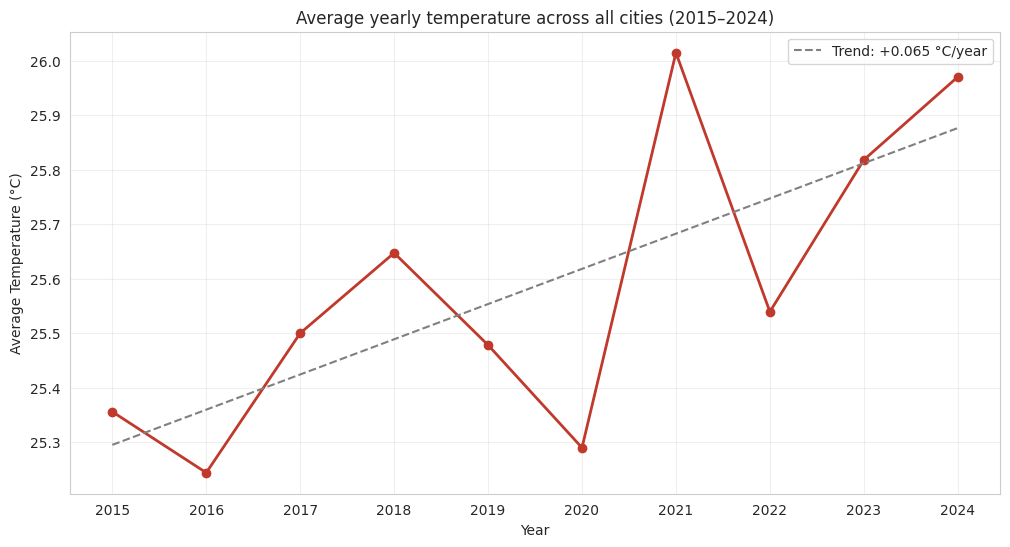

Year
2015    25.36
2016    25.24
2017    25.50
2018    25.65
2019    25.48
2020    25.29
2021    26.01
2022    25.54
2023    25.82
2024    25.97
Name: Temperature, dtype: float64

Slope: +0.065 °C per year  (~+0.65 °C over the decade)


In [11]:
# ===== Yearly temperature trend (2015–2024) =====
df["Year"] = df["datetime"].dt.year

yearly = df.groupby("Year")["Temperature"].mean()

plt.figure(figsize=(12, 6))
plt.plot(yearly.index, yearly.values, marker="o", linewidth=2, color="#c0392b")

# linear trend line
z = np.polyfit(yearly.index, yearly.values, 1)
trend = np.poly1d(z)
plt.plot(yearly.index, trend(yearly.index), "--", color="gray",
         label=f"Trend: {z[0]:+.3f} °C/year")

plt.title("Average yearly temperature across all cities (2015–2024)")
plt.xlabel("Year")
plt.ylabel("Average Temperature (°C)")
plt.xticks(yearly.index)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(yearly.round(2))
print(f"\nSlope: {z[0]:+.3f} °C per year  (~{z[0]*10:+.2f} °C over the decade)")

Average temperature shows a slight upward trend of about +0.065 °C/year (~0.65 °C over the decade), consistent with broader climate-warming expectations. However, year-to-year variability is large relative to the trend (e.g. a 2021 peak, 2016/2020 dips), so 10 years is too short to draw strong climate conclusions. The trend is suggestive, not conclusive — but relevant for long-term planning toward 2034.

Hour × Month heatmap: For each city, I map average temperature across hour-of-day (y) and month (x). This reveals not just which months but which hours are comfortable — even hot months have cool evening/night windows suitable for matches.

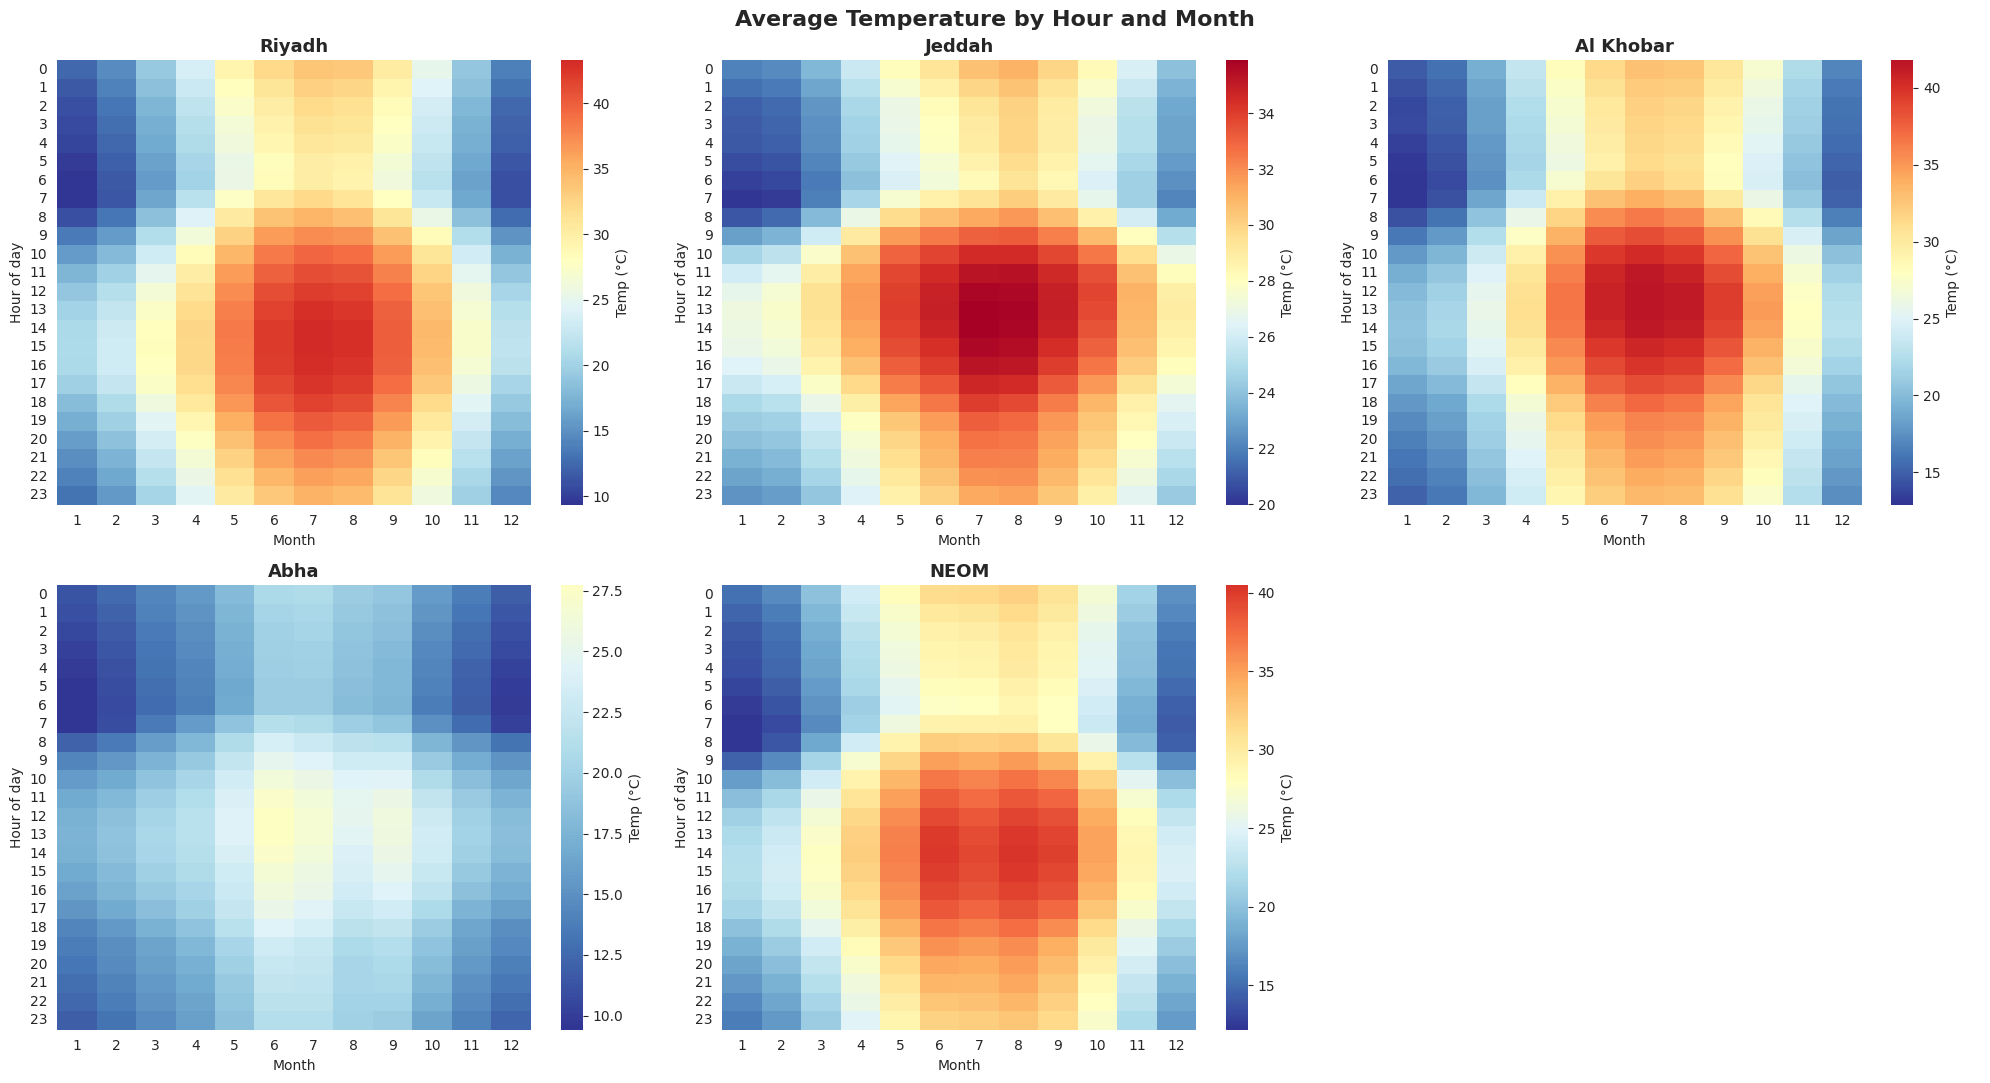

In [12]:
# ===== Hour × Month temperature heatmap per city =====
cities = df["City"].unique()
fig, axes = plt.subplots(2, 3, figsize=(20, 11))

for ax, city in zip(axes.flat, cities):
    sub = df[df["City"] == city]
    pivot = sub.pivot_table(index="Hour", columns="Month",
                            values="Temperature", aggfunc="mean")
    sns.heatmap(pivot, ax=ax, cmap="RdYlBu_r", center=28,
                cbar_kws={"label": "Temp (°C)"})
    ax.set_title(city, fontsize=13, fontweight="bold")
    ax.set_xlabel("Month")
    ax.set_ylabel("Hour of day")

# hide the 6th empty panel (we have 5 cities)
axes.flat[-1].axis("off")

plt.suptitle("Average Temperature by Hour and Month", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

A clear "red-cross" pattern: midday summer (months 5–9, hours 12–17) is hottest, while winter and night/early-morning hours stay coolest. Crucially, even in hot months the evening/night rows remain cooler — defining a viable match window. Abha is uniformly cool (peaks below 27.5°C), viable year-round. Riyadh/NEOM allow summer matches only at night. Jeddah and Al Khobar show a vertically wider hot block and warmer nights (coastal humidity traps heat), making them the most constrained. Since this maps temperature only, a WBGT-based heatmap will better reflect true comfort for the humid cities.



Daily (diurnal) pattern: I plot average temperature across the 24 hours for each city to pinpoint the coolest hours — directly informing match kickoff times.

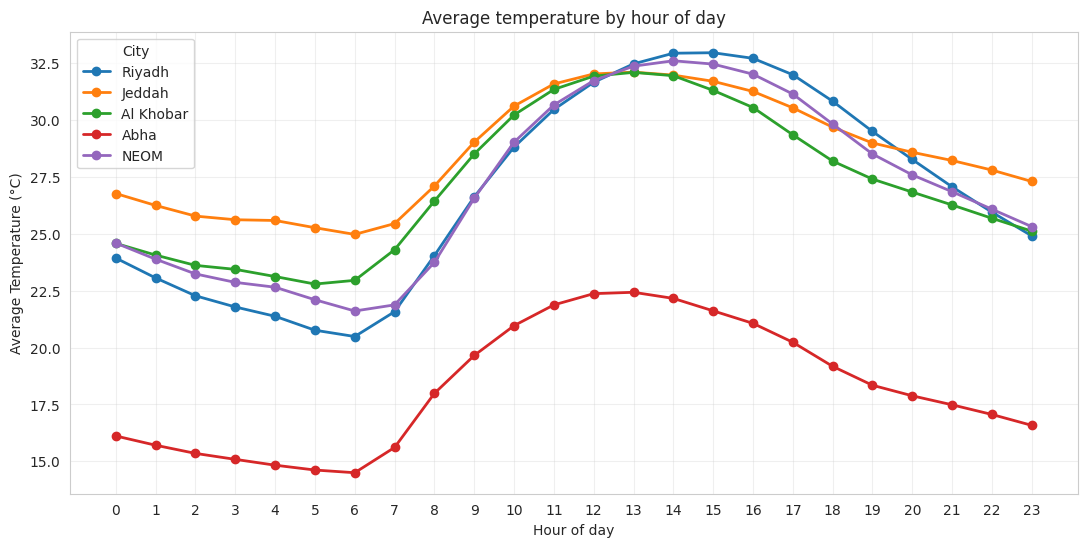

Coolest hour per city:
          City  Hour  Temperature
6         Abha     6         14.5
29   Al Khobar     5         22.8
54      Jeddah     6         25.0
78        NEOM     6         21.6
102     Riyadh     6         20.5

Hottest hour per city:
          City  Hour  Temperature
13        Abha    13         22.4
37   Al Khobar    13         32.1
61      Jeddah    13         32.1
86        NEOM    14         32.6
111     Riyadh    15         33.0


In [13]:
# ===== Diurnal pattern: temperature by hour of day =====
hourly = df.groupby(["City", "Hour"])["Temperature"].mean().reset_index()

plt.figure(figsize=(13, 6))
for city in df["City"].unique():
    sub = hourly[hourly["City"] == city]
    plt.plot(sub["Hour"], sub["Temperature"], marker="o", label=city, linewidth=2)

plt.title("Average temperature by hour of day")
plt.xlabel("Hour of day")
plt.ylabel("Average Temperature (°C)")
plt.xticks(range(0, 24))
plt.legend(title="City")
plt.grid(alpha=0.3)
plt.show()

# coolest & hottest hour per city
print("Coolest hour per city:")
print(hourly.loc[hourly.groupby("City")["Temperature"].idxmin()][["City","Hour","Temperature"]].round(1))
print("\nHottest hour per city:")
print(hourly.loc[hourly.groupby("City")["Temperature"].idxmax()][["City","Hour","Temperature"]].round(1))

All cities are coolest around 05:00–06:00 (pre-sunrise) and peak at 13:00–15:00 — the peak lags solar noon by 1–2 hours due to thermal storage. Since dawn matches are impractical, the realistic comfortable window is evening onward (≈18:00–22:00). Inland cities (Riyadh, NEOM) cool down faster after sunset, while Jeddah stays warm late into the night (still ~27°C at 23:00), confirming it needs the latest kickoff times.

Correlation: I examine how the numeric weather variables relate to each other — to understand the data and to spot redundant features before modeling.

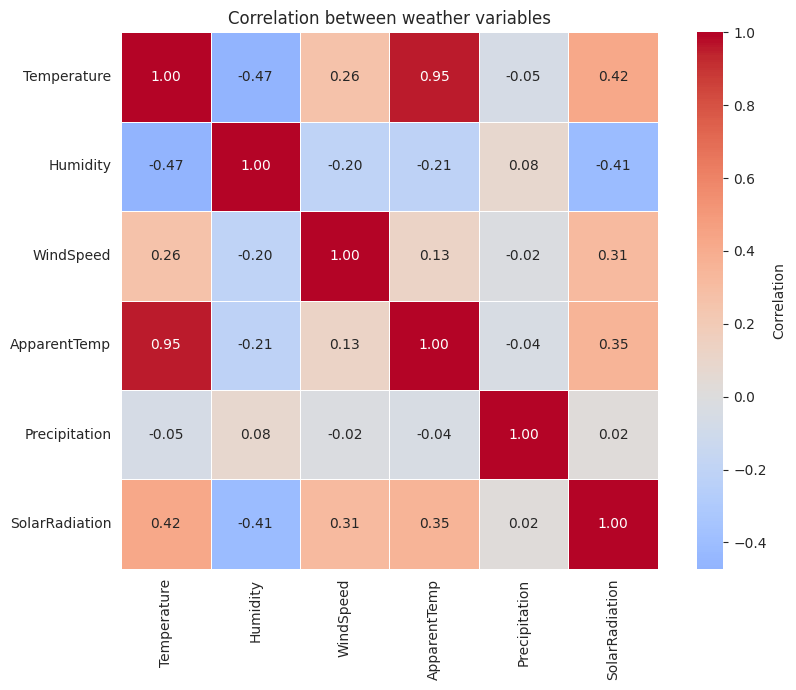

In [14]:
# ===== Correlation heatmap of weather variables =====
num_cols = ["Temperature", "Humidity", "WindSpeed",
            "ApparentTemp", "Precipitation", "SolarRadiation"]

corr = df[num_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"label": "Correlation"})
plt.title("Correlation between weather variables")
plt.tight_layout()
plt.show()

Temperature and ApparentTemp are almost identical (0.95) — redundant, so only one (or a combined index) should be used. Temperature–Humidity is moderately negative (-0.47): related but not redundant, so both add value — motivating a combined comfort index (WBGT). SolarRadiation and WindSpeed carry independent information. Precipitation correlates weakly with everything (~0), confirming it is a low-value feature in this arid climate.



# 2. Feature Engineering


WBGT (Wet-Bulb Globe Temperature): a heat-stress index combining temperature and humidity. I compute the simplified form (sWBGT) used in sports medicine, then derive a match-suitability class from it.

In [15]:
# ===== Feature 1: WBGT heat-stress index =====
# Simplified WBGT (sWBGT) used in sports/heat-stress guidelines:
#   es = 6.105 * exp(17.27*T / (237.7+T))   -> saturation vapor pressure (hPa)
#   e  = es * RH/100                          -> actual vapor pressure
#   WBGT = 0.567*T + 0.393*e + 3.94
# Note: sWBGT tends to over-estimate stress in hot-humid areas (Jeddah, Al Khobar).

def compute_wbgt(temp_c, rh):
    es = 6.105 * np.exp(17.27 * temp_c / (237.7 + temp_c))
    e = es * rh / 100.0
    return 0.567 * temp_c + 0.393 * e + 3.94

df["WBGT"] = compute_wbgt(df["Temperature"], df["Humidity"]).round(2)

# quick check
print(df[["City","Temperature","Humidity","WBGT"]].head())
print("\nWBGT range:", df["WBGT"].min(), "->", df["WBGT"].max())
print("\nMean WBGT by city:")
print(df.groupby("City")["WBGT"].mean().round(1).sort_values())

     City  Temperature  Humidity   WBGT
0  Riyadh         12.9        50  14.17
1  Riyadh         11.7        54  13.49
2  Riyadh         10.5        59  12.83
3  Riyadh          9.7        62  12.37
4  Riyadh          9.2        65  12.12

WBGT range: 4.54 -> 42.08

Mean WBGT by city:
City
Abha         18.5
Riyadh       22.2
NEOM         23.7
Al Khobar    26.6
Jeddah       29.6
Name: WBGT, dtype: float64


WBGT reorders the cities compared to temperature alone. Riyadh and Jeddah had similar temperatures (~27 vs 28.5°C) but their WBGT differs sharply (22.2 vs 29.6) — a 7.4-point heat-stress gap. This is because WBGT accounts for humidity: dry-hot Riyadh is far less stressful than humid-hot Jeddah. This confirms WBGT captures real comfort that raw temperature misses, and justifies it as the basis for match-suitability classification.

### Before / After — Raw Temperature vs WBGT

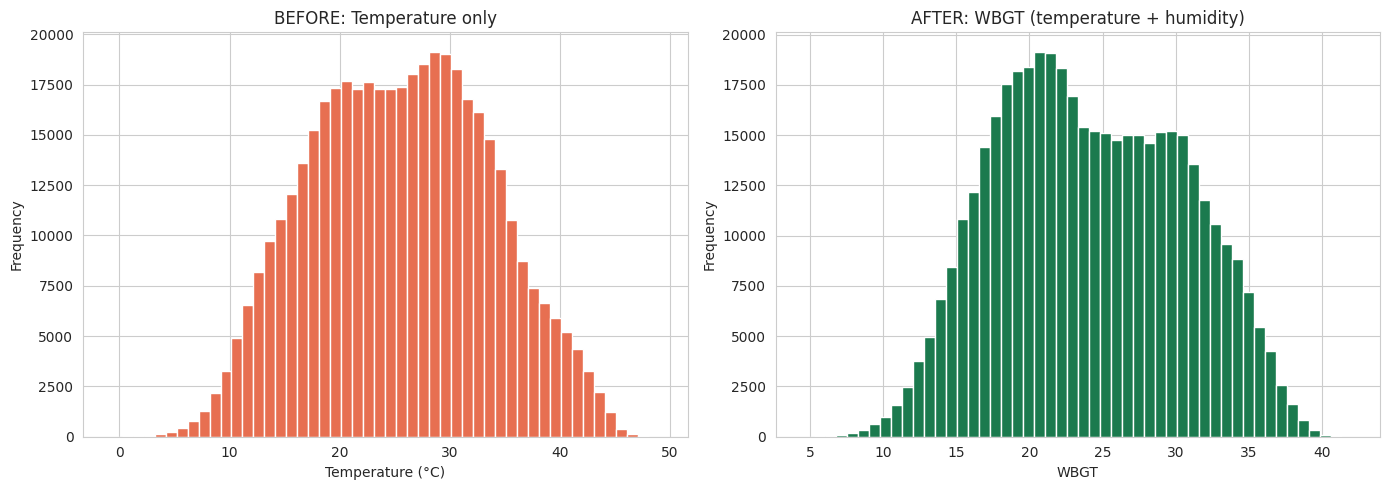

           Temperature  Humidity  WBGT
City                                  
Abha              18.3      53.1  18.5
Al Khobar         27.2      53.1  26.6
Jeddah            28.5      62.6  29.6
NEOM              27.0      32.9  23.7
Riyadh            26.9      26.5  22.2


In [16]:
# ===== Before vs After: temperature alone vs WBGT =====
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df["Temperature"], bins=50, color="#e76f51", edgecolor="white")
axes[0].set_title("BEFORE: Temperature only")
axes[0].set_xlabel("Temperature (°C)"); axes[0].set_ylabel("Frequency")

axes[1].hist(df["WBGT"], bins=50, color="#1b7a4e", edgecolor="white")
axes[1].set_title("AFTER: WBGT (temperature + humidity)")
axes[1].set_xlabel("WBGT"); axes[1].set_ylabel("Frequency")

plt.tight_layout(); plt.show()

# show how the same temperature maps to different WBGT depending on humidity
print(df.groupby("City")[["Temperature","Humidity","WBGT"]].mean().round(1))

Before, we only had temperature. After feature engineering, WBGT combines temperature and humidity into one heat-stress index. The table shows the effect: Riyadh and Jeddah have similar temperatures but very different WBGT (humidity makes Jeddah more stressful), which raw temperature alone could not capture.

Target variable (Match Suitability): I convert the numeric WBGT into 3 classes based on athletic heat-stress thresholds. This becomes the label the classification model will predict.

In [17]:
# ===== Feature 2: Match-suitability target from WBGT =====
# Thresholds based on outdoor-sport heat-stress guidelines:
#   WBGT < 28        -> Suitable
#   28 <= WBGT < 32  -> Caution
#   WBGT >= 32       -> Not Suitable
def suitability_class(wbgt):
    if wbgt < 28:
        return "Suitable"
    elif wbgt < 32:
        return "Caution"
    else:
        return "Not Suitable"

df["MatchSuitability"] = df["WBGT"].apply(suitability_class)

# class balance — important to check before modeling
print("Class distribution:")
print(df["MatchSuitability"].value_counts())
print("\nPercentage:")
print((df["MatchSuitability"].value_counts(normalize=True) * 100).round(1))

print("\nClass distribution by city:")
print(df.groupby("City")["MatchSuitability"].value_counts().unstack().fillna(0).astype(int))

Class distribution:
MatchSuitability
Suitable        305133
Caution          77061
Not Suitable     56166
Name: count, dtype: int64

Percentage:
MatchSuitability
Suitable        69.6
Caution         17.6
Not Suitable    12.8
Name: proportion, dtype: float64

Class distribution by city:
MatchSuitability  Caution  Not Suitable  Suitable
City                                             
Abha                    0             0     87672
Al Khobar           17500         21127     49045
Jeddah              26837         30606     30229
NEOM                18850          3895     64927
Riyadh              13874           538     73260




The target is imbalanced: Suitable 69.6%, Caution 17.6%, Not Suitable 12.8%. So evaluation will rely on macro F1-score and the confusion matrix rather than accuracy alone, and models will use class_weight="balanced". By city, Abha is 100% Suitable (year-round viable), Riyadh is 84% Suitable, while Jeddah is the most constrained (lowest Suitable share, highest Not-Suitable count). This matches the EDA findings and quantifies the scheduling difficulty per city.

Cyclical encoding: Hour and Month are circular (hour 23 is next to hour 0; month 12 is next to month 1). Encoding them as plain numbers loses this. I transform them with sin/cos so the model understands the cycle.

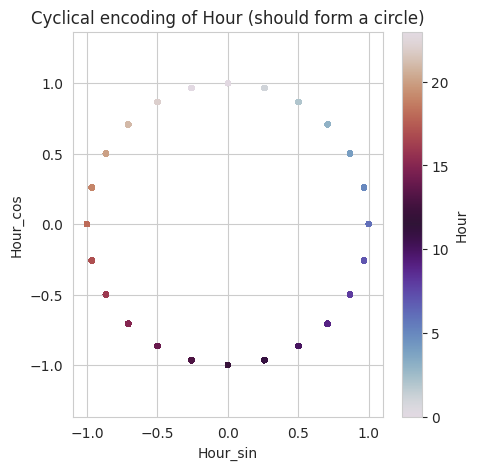

,Hour,Hour_sin,Hour_cos,Month,Month_sin,Month_cos
0,0,0.000000,1.000000,1,0.5,0.866025
1,1,0.258819,0.965926,1,0.5,0.866025
2,2,0.500000,0.866025,1,0.5,0.866025
3,3,0.707107,0.707107,1,0.5,0.866025
4,4,0.866025,0.500000,1,0.5,0.866025


In [18]:
# ===== Feature 3: Cyclical encoding for Hour and Month =====
# Plain numbers imply 23 is far from 0, but they are actually adjacent (1 hour apart).
# sin/cos mapping places them correctly on a circle.

df["Hour_sin"]  = np.sin(2 * np.pi * df["Hour"] / 24)
df["Hour_cos"]  = np.cos(2 * np.pi * df["Hour"] / 24)
df["Month_sin"] = np.sin(2 * np.pi * df["Month"] / 12)
df["Month_cos"] = np.cos(2 * np.pi * df["Month"] / 12)

# quick visual check: plotting the two hour components should form a circle
plt.figure(figsize=(5, 5))
plt.scatter(df["Hour_sin"], df["Hour_cos"], c=df["Hour"], cmap="twilight", s=10)
plt.xlabel("Hour_sin"); plt.ylabel("Hour_cos")
plt.title("Cyclical encoding of Hour (should form a circle)")
plt.colorbar(label="Hour")
plt.axis("equal")
plt.show()

df[["Hour","Hour_sin","Hour_cos","Month","Month_sin","Month_cos"]].head()



The sin/cos encoding produces a clean circle, confirming the transformation is correct: hour 23 wraps around next to hour 0, so the model now treats them as adjacent rather than far apart. The same applies to months (December next to January).

### Before / After — Cyclical Encoding of Hour

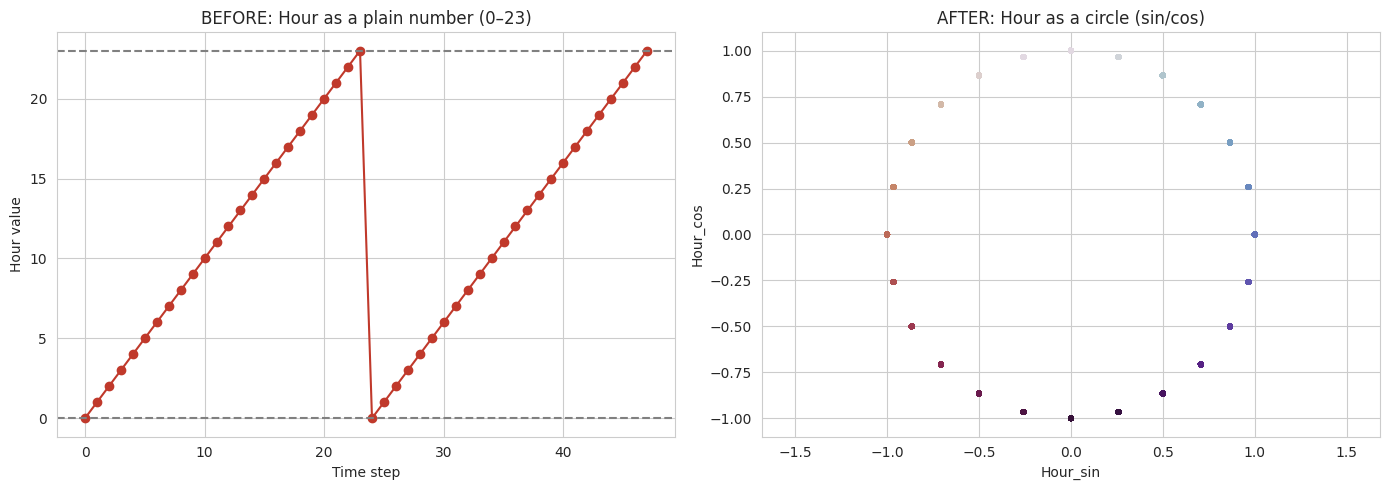

In [19]:
# ===== Before vs After: cyclical encoding =====
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# BEFORE: hour as a plain number (0-23 on a line)
sample = df[df["City"] == "Riyadh"].head(48)
axes[0].plot(range(len(sample)), sample["Hour"], marker="o", color="#c0392b")
axes[0].set_title("BEFORE: Hour as a plain number (0–23)")
axes[0].set_xlabel("Time step"); axes[0].set_ylabel("Hour value")
axes[0].axhline(23, ls="--", c="gray"); axes[0].axhline(0, ls="--", c="gray")

# AFTER: hour as a circle (sin/cos)
axes[1].scatter(df["Hour_sin"], df["Hour_cos"], c=df["Hour"], cmap="twilight", s=10)
axes[1].set_title("AFTER: Hour as a circle (sin/cos)")
axes[1].set_xlabel("Hour_sin"); axes[1].set_ylabel("Hour_cos")
axes[1].axis("equal")

plt.tight_layout(); plt.show()

Before encoding, hour 23 and hour 0 look far apart (23 vs 0) even though they are 1 hour apart. After cyclical encoding they sit next to each other on a circle, so the model correctly treats midnight and 1 AM as neighbours.

### Feature — City Encoding (One-Hot)

In [20]:
# ===== City encoding: convert city names to numeric columns =====
# Models can't read text like "Riyadh", so we one-hot encode the city.
city_encoded = pd.get_dummies(df["City"], prefix="City")
df = pd.concat([df, city_encoded], axis=1)

print("New encoded columns:", list(city_encoded.columns))
print(df[["City"] + list(city_encoded.columns)].head())

New encoded columns: ['City_Abha', 'City_Al Khobar', 'City_Jeddah', 'City_NEOM', 'City_Riyadh']
     City  City_Abha  City_Al Khobar  City_Jeddah  City_NEOM  City_Riyadh
0  Riyadh      False           False        False      False         True
1  Riyadh      False           False        False      False         True
2  Riyadh      False           False        False      False         True
3  Riyadh      False           False        False      False         True
4  Riyadh      False           False        False      False         True


Machine-learning models work with numbers, not text. One-hot encoding turns the single City column into 5 binary columns (one per city), where each row has True in its own city's column. This lets the model distinguish cities without implying any false order between them.

Lag features: To make this a real forecasting problem, I predict suitability a few hours ahead using past weather. Lag features give the model "memory" of recent conditions. Crucially, lags are computed within each city to avoid mixing data across cities.

In [21]:
# ===== Feature 4: Lag features + future target (forecasting setup) =====
# Goal: predict conditions HORIZON hours into the future from PAST data.
# CRITICAL: sort by city+time, and compute lags WITHIN each city (groupby),
# otherwise a lag could pull a value from a different city.

HORIZON = 3  # predict 3 hours ahead

# 1) make sure data is ordered correctly
df = df.sort_values(["City", "datetime"]).reset_index(drop=True)

# 2) lag features: weather from 1, 2, 3, and 24 hours ago (per city)
lag_cols = ["Temperature", "Humidity", "WindSpeed", "WBGT"]
for col in lag_cols:
    for lag in [1, 2, 3, 24]:
        df[f"{col}_lag{lag}"] = df.groupby("City")[col].shift(lag)

# 3) rolling means (last 6h and 24h), per city
for col in ["Temperature", "WBGT"]:
    df[f"{col}_roll6"]  = df.groupby("City")[col].shift(1).rolling(6).mean().reset_index(0, drop=True)
    df[f"{col}_roll24"] = df.groupby("City")[col].shift(1).rolling(24).mean().reset_index(0, drop=True)

# 4) FUTURE target: suitability HORIZON hours ahead (per city)
df["target"] = df.groupby("City")["MatchSuitability"].shift(-HORIZON)

# 5) drop rows with NaN created by shifting (edges of each city's series)
before = len(df)
df_model = df.dropna(subset=[f"{c}_lag24" for c in lag_cols] + ["target"]).reset_index(drop=True)
after = len(df_model)

print(f"Rows before: {before:,}  ->  after dropping NaN: {after:,}  (lost {before-after:,})")
print("\nNew columns added:")
print([c for c in df_model.columns if "lag" in c or "roll" in c or c=="target"])
print("\nTarget distribution (future):")
print(df_model["target"].value_counts())

Rows before: 438,360  ->  after dropping NaN: 438,225  (lost 135)

New columns added:
['Temperature_lag1', 'Temperature_lag2', 'Temperature_lag3', 'Temperature_lag24', 'Humidity_lag1', 'Humidity_lag2', 'Humidity_lag3', 'Humidity_lag24', 'WindSpeed_lag1', 'WindSpeed_lag2', 'WindSpeed_lag3', 'WindSpeed_lag24', 'WBGT_lag1', 'WBGT_lag2', 'WBGT_lag3', 'WBGT_lag24', 'Temperature_roll6', 'Temperature_roll24', 'WBGT_roll6', 'WBGT_roll24', 'target']

Target distribution (future):
target
Suitable        305008
Caution          77051
Not Suitable     56166
Name: count, dtype: int64


In [22]:
# Correct leakage check: look at the actual first row of each city by position
df_sorted = df.sort_values(["City","datetime"])
first_idx = df_sorted.groupby("City").head(1).index

print("Actual first row per city (lag1 MUST be NaN):")
print(df_sorted.loc[first_idx, ["City","datetime","Temperature","Temperature_lag1"]])

# count NaN in lag1 per city — should be exactly 1 per city (5 total)
print("\nNaN count in Temperature_lag1 per city :")
print(df.groupby("City")["Temperature_lag1"].apply(lambda s: s.isna().sum()))

Actual first row per city (lag1 MUST be NaN):
             City   datetime  Temperature  Temperature_lag1
0            Abha 2015-01-01         12.2               NaN
87672   Al Khobar 2015-01-01         15.2               NaN
175344     Jeddah 2015-01-01         22.7               NaN
263016       NEOM 2015-01-01         17.4               NaN
350688     Riyadh 2015-01-01         12.9               NaN

NaN count in Temperature_lag1 per city :
City
Abha         1
Al Khobar    1
Jeddah       1
NEOM         1
Riyadh       1
Name: Temperature_lag1, dtype: int64


In [23]:
# ===== Final dataset overview after feature engineering =====
print("Shape:", df_model.shape)
print("\nAll columns:")
print(list(df_model.columns))

print("\nFirst rows (sample of key columns):")
cols_to_show = ["City","datetime","Temperature","Humidity","WBGT",
                "Temperature_lag1","WBGT_lag24","WBGT_roll6",
                "Hour_sin","Month_sin","MatchSuitability","target"]
df_model[cols_to_show].head(10)

Shape: (438225, 44)

All columns:
['City', 'datetime', 'Temperature', 'Humidity', 'WindSpeed', 'ApparentTemp', 'Precipitation', 'SolarRadiation', 'Hour', 'Month', 'DayOfWeek', 'Year', 'WBGT', 'MatchSuitability', 'Hour_sin', 'Hour_cos', 'Month_sin', 'Month_cos', 'City_Abha', 'City_Al Khobar', 'City_Jeddah', 'City_NEOM', 'City_Riyadh', 'Temperature_lag1', 'Temperature_lag2', 'Temperature_lag3', 'Temperature_lag24', 'Humidity_lag1', 'Humidity_lag2', 'Humidity_lag3', 'Humidity_lag24', 'WindSpeed_lag1', 'WindSpeed_lag2', 'WindSpeed_lag3', 'WindSpeed_lag24', 'WBGT_lag1', 'WBGT_lag2', 'WBGT_lag3', 'WBGT_lag24', 'Temperature_roll6', 'Temperature_roll24', 'WBGT_roll6', 'WBGT_roll24', 'target']

First rows (sample of key columns):


,City,datetime,Temperature,Humidity,WBGT,Temperature_lag1,WBGT_lag24,WBGT_roll6,Hour_sin,Month_sin,MatchSuitability,target
0,Abha,2015-01-02 00:00:00,12.1,42,13.13,12.8,13.64,16.255000,0.000000,0.5,Suitable,Suitable
1,Abha,2015-01-02 01:00:00,11.4,36,12.31,12.1,13.06,15.446667,0.258819,0.5,Suitable,Suitable
2,Abha,2015-01-02 02:00:00,10.8,32,11.69,11.4,12.43,14.581667,0.500000,0.5,Suitable,Suitable
3,Abha,2015-01-02 03:00:00,10.2,31,11.24,10.8,11.96,13.688333,0.707107,0.5,Suitable,Suitable
4,Abha,2015-01-02 04:00:00,9.7,32,10.95,10.2,11.54,12.896667,0.866025,0.5,Suitable,Suitable
5,Abha,2015-01-02 05:00:00,9.3,35,10.82,9.7,11.37,12.216667,0.965926,0.5,Suitable,Suitable
6,Abha,2015-01-02 06:00:00,9.2,35,10.75,9.3,11.25,11.690000,1.000000,0.5,Suitable,Suitable
7,Abha,2015-01-02 07:00:00,9.5,34,10.91,9.2,11.21,11.293333,0.965926,0.5,Suitable,Suitable
8,Abha,2015-01-02 08:00:00,11.2,39,12.33,9.5,12.61,11.060000,0.866025,0.5,Suitable,Suitable
9,Abha,2015-01-02 09:00:00,16.8,17,14.74,11.2,14.59,11.166667,0.707107,0.5,Suitable,Suitable


The final modeling dataset has 438,225 rows × 39 columns. Each row now carries the raw weather, WBGT, cyclical time encodings, lagged values (1/2/3/24h), rolling means, the current suitability label, and the future target (+3h). Spot-checking confirms lags align with previous hours and the series correctly starts after the first 24h were dropped. The dataset is model-ready.

In [24]:
df_model.to_csv("dataset_features.csv", index=False)

## Final Insight — Scheduling Recommendation

Bringing all the analysis together, the data points to a clear scheduling strategy:

- **Best months:** November–February are the coolest (avg ~17–19°C); summer
  (Jun–Aug, ~32°C) is unsuitable for daytime play.
- **Best kickoff time:** all cities are coolest at dawn and hottest at 13:00–15:00.
  Since dawn is impractical, the realistic window is the **evening (≈18:00–22:00)**.
- **City-specific:** **Abha** is comfortable year-round (highest comfort, most stable).
  **Riyadh** and **NEOM** are hot but dry, so manageable. **Jeddah** and **Al Khobar**
  are the most constrained (high humidity → high WBGT) and need the latest kickoffs.
- **Why WBGT matters:** Riyadh and Jeddah have similar temperatures (~27–28°C) but very
  different heat stress (WBGT 22 vs 30), so humidity — not temperature alone — drives
  the scheduling decision.

**Bottom line:** schedule matches in winter months, in the evening, and give the humid
coastal cities (Jeddah, Al Khobar) the latest kickoff slots. The next phase will turn
these descriptive insights into a predictive model for automated scheduling support.